<a href="https://colab.research.google.com/github/sastha-06/24ADI006_DL_24BAD106/blob/main/24BAD106_DL_EX7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Sastha Jeyasri A.
Roll No: 24BAD106
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Number of training images: 60000
Number of testing images: 10000
Image dimensions: (28, 28)


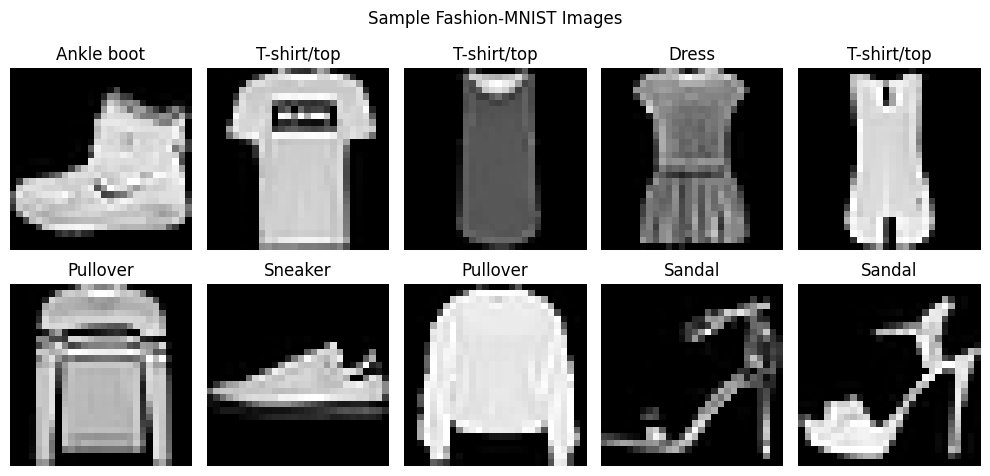

Minimum pixel value: -1.0
Maximum pixel value: 1.0
Reshaped training data: (60000, 28, 28, 1)
Image shape: (28, 28, 1)
Batch size: 128
Number of batches per epoch: 468
One batch shape: (128, 28, 28, 1)


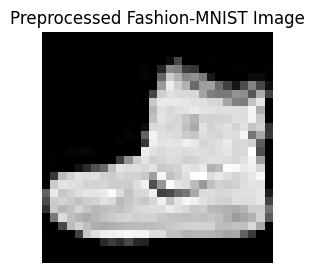

Part A completed successfully.


In [ ]:
# Name: Sastha Jeyasri A.
# Roll No: 24BAD106
# PART A: DATASET PREPARATION AND IMAGE PREPROCESSING

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

# Step 1: Load Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Number of training images:", len(x_train))
print("Number of testing images:", len(x_test))
print("Image dimensions:", x_train.shape[1:])

# Step 2: Display sample images
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()

# Step 3: Normalize pixel values to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

print("Minimum pixel value:", np.min(x_train))
print("Maximum pixel value:", np.max(x_train))

# Step 4: Reshape images to include channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Reshaped training data:", x_train.shape)
print("Image shape:", x_train.shape[1:])

# Step 5: Create a batch-wise TensorFlow data pipeline
BATCH_SIZE = 128
BUFFER_SIZE = 60000

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Batch size:", BATCH_SIZE)
print("Number of batches per epoch:", len(train_dataset))

for image_batch in train_dataset.take(1):
    print("One batch shape:", image_batch.shape)

# Step 6: Display a preprocessed image
plt.figure(figsize=(3, 3))
plt.imshow((x_train[0, :, :, 0] + 1) / 2, cmap="gray")
plt.title("Preprocessed Fashion-MNIST Image")
plt.axis("off")
plt.show()

print("Part A completed successfully.")

Name: Sastha Jeyasri A.
Roll No: 24BAD106
Random noise vector size: 100

Generator created successfully!
Generator output shape: (None, 28, 28, 1)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)


Noise input shape: (1, 100)
Generated image shape: (1, 28, 28, 1)


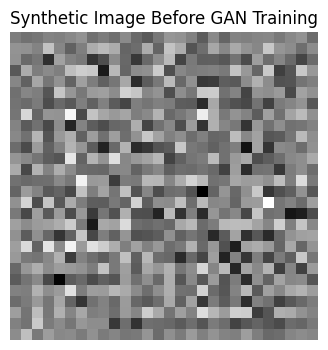

Part B completed successfully.


In [ ]:

# Name: Sastha Jeyasri A.
# Roll No: 24BAD106
# PART B: IMPLEMENTING THE GENERATOR

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

# Step 1: Define the random noise vector size
NOISE_DIM = 100

print("Random noise vector size:", NOISE_DIM)

# Step 2: Build the Generator model
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),

    # Convert noise into initial image features
    tf.keras.layers.Dense(7 * 7 * 128, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),

    # Reshape into a feature map
    tf.keras.layers.Reshape((7, 7, 128)),

    # Upsample from 7x7 to 14x14
    tf.keras.layers.Conv2DTranspose(
        64, kernel_size=4, strides=2,
        padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),

    # Upsample from 14x14 to 28x28
    tf.keras.layers.Conv2DTranspose(
        1, kernel_size=4, strides=2,
        padding="same", activation="tanh"
    )
], name="Generator")

print("\nGenerator created successfully!")
print("Generator output shape:", generator.output_shape)

# Step 3: Display the Generator model summary
generator.summary()

# Step 4: Generate an image before training
noise = tf.random.normal([1, NOISE_DIM])
generated_image = generator(noise, training=False)

print("\nNoise input shape:", noise.shape)
print("Generated image shape:", generated_image.shape)

# Step 5: Display the generated image
# Convert pixel values from [-1, 1] to [0, 1]
plt.figure(figsize=(4, 4))
plt.imshow(
    (generated_image[0, :, :, 0].numpy() + 1) / 2,
    cmap="gray"
)
plt.title("Synthetic Image Before GAN Training")
plt.axis("off")
plt.show()

# Step 6: Display Generator architecture
tf.keras.utils.plot_model(
    generator,
    show_shapes=True,
    show_layer_names=True
)

print("Part B completed successfully.")

In [ ]:

# Name: Sastha Jeyasri A.
# Roll No: 24BAD106
# PART C: IMPLEMENTING THE DISCRIMINATOR AND GAN MODEL

import tensorflow as tf
import numpy as np

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

# Step 1: Define the random noise vector size
NOISE_DIM = 100

# Step 2: Build the Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),
    tf.keras.layers.Dense(7 * 7 * 128, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Reshape((7, 7, 128)),
    tf.keras.layers.Conv2DTranspose(
        64, 4, strides=2, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Conv2DTranspose(
        1, 4, strides=2, padding="same", activation="tanh"
    )
], name="Generator")

print("\nGenerator created successfully!")

# Step 3: Build the Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(
        64, kernel_size=4, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv2D(
        128, kernel_size=4, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="Discriminator")

print("Discriminator created successfully!")

# Step 4: Compile the Discriminator
discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002, beta_1=0.5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Discriminator compiled successfully!")

# Step 5: Freeze the Discriminator for GAN training
discriminator.trainable = False

# Step 6: Combine Generator and Discriminator
gan_input = tf.keras.layers.Input(shape=(NOISE_DIM,))
generated_image = generator(gan_input)
gan_output = discriminator(generated_image)

gan = tf.keras.Model(
    gan_input, gan_output, name="GAN"
)

gan.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002, beta_1=0.5
    ),
    loss="binary_crossentropy"
)

print("GAN model created and compiled successfully!")

# Step 7: Display Generator summary
print("\nGENERATOR MODEL SUMMARY")
generator.summary()

# Step 8: Display Discriminator summary
print("\nDISCRIMINATOR MODEL SUMMARY")
discriminator.summary()

# Step 9: Display GAN summary
print("\nGAN MODEL SUMMARY")
gan.summary()

# Step 10: Test the models with random noise
noise = tf.random.normal([1, NOISE_DIM])
fake_images = generator(noise, training=False)
prediction = discriminator(fake_images, training=False)

print("\nNoise input shape:", noise.shape)
print("Generated image shape:", fake_images.shape)
print("Discriminator prediction shape:", prediction.shape)
print("Discriminator prediction:", prediction.numpy()[0][0])

print("\nPart C completed successfully.")

Name: Sastha Jeyasri A.
Roll No: 24BAD106

Generator created successfully!
Discriminator created successfully!
Discriminator compiled successfully!
GAN model created and compiled successfully!

GENERATOR MODEL SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 151,233 (590.75 KB)


Noise input shape: (1, 100)
Generated image shape: (1, 28, 28, 1)
Discriminator prediction shape: (1, 1)
Discriminator prediction: 0.5010348

Part C completed successfully.


Name: Sastha Jeyasri A.
Roll No: 24BAD106
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/30 | G Loss: 0.7747 | D Loss: 1.3778


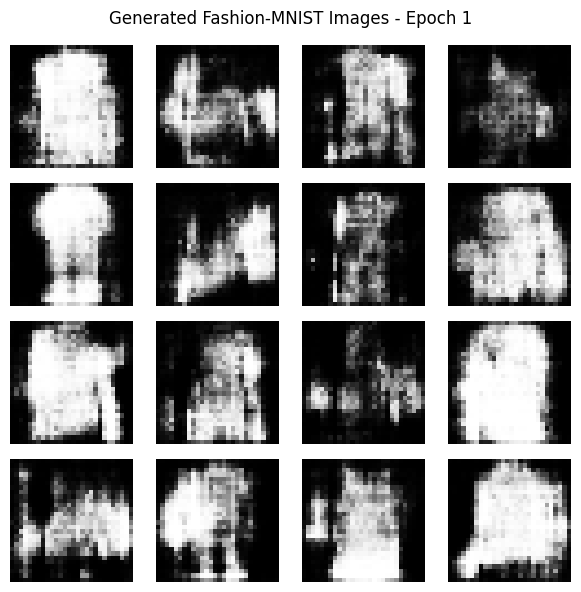

Epoch 2/30 | G Loss: 0.8671 | D Loss: 1.3356
Epoch 3/30 | G Loss: 0.9202 | D Loss: 1.3076
Epoch 4/30 | G Loss: 0.8622 | D Loss: 1.3515
Epoch 5/30 | G Loss: 0.8480 | D Loss: 1.3657


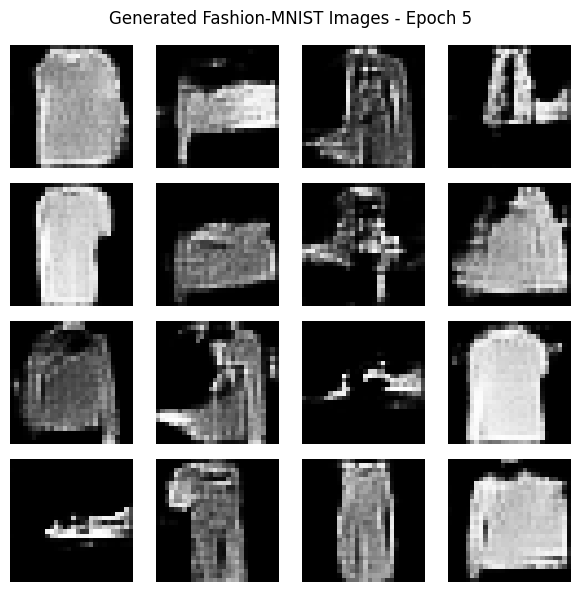

Epoch 6/30 | G Loss: 0.8368 | D Loss: 1.3658
Epoch 7/30 | G Loss: 0.8342 | D Loss: 1.3683
Epoch 8/30 | G Loss: 0.8330 | D Loss: 1.3692
Epoch 9/30 | G Loss: 0.8307 | D Loss: 1.3704
Epoch 10/30 | G Loss: 0.8293 | D Loss: 1.3704


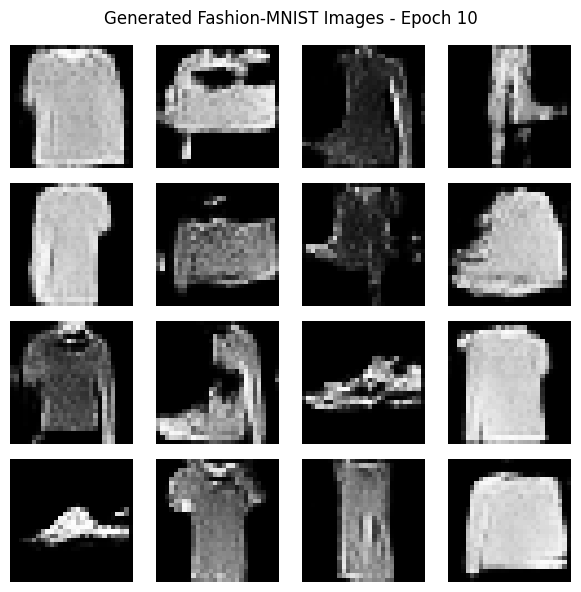

Epoch 11/30 | G Loss: 0.8282 | D Loss: 1.3690
Epoch 12/30 | G Loss: 0.8264 | D Loss: 1.3697
Epoch 13/30 | G Loss: 0.8265 | D Loss: 1.3701
Epoch 14/30 | G Loss: 0.8261 | D Loss: 1.3706
Epoch 15/30 | G Loss: 0.8268 | D Loss: 1.3700


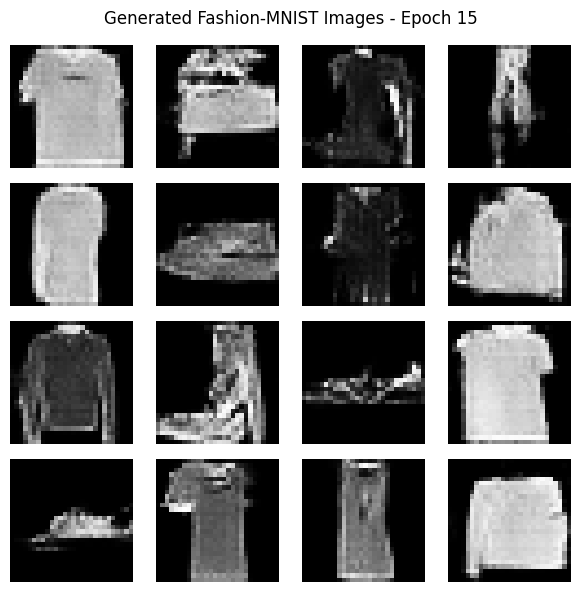

Epoch 16/30 | G Loss: 0.8267 | D Loss: 1.3702
Epoch 17/30 | G Loss: 0.8263 | D Loss: 1.3706
Epoch 18/30 | G Loss: 0.8274 | D Loss: 1.3715
Epoch 19/30 | G Loss: 0.8274 | D Loss: 1.3716
Epoch 20/30 | G Loss: 0.8240 | D Loss: 1.3712


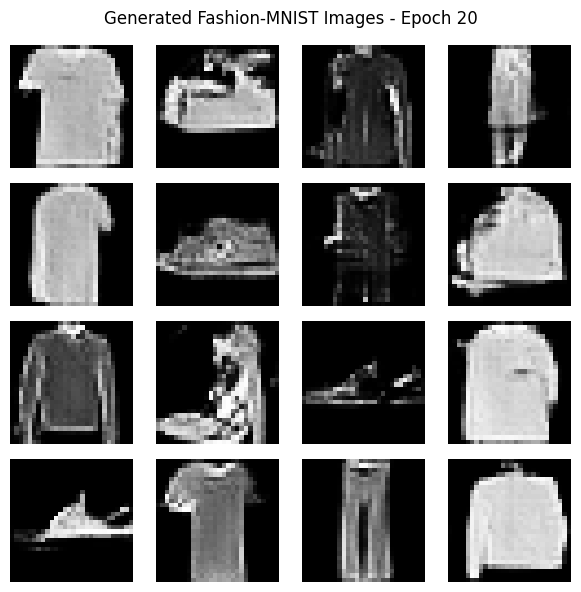

Epoch 21/30 | G Loss: 0.8245 | D Loss: 1.3726
Epoch 22/30 | G Loss: 0.8275 | D Loss: 1.3731
Epoch 23/30 | G Loss: 0.8229 | D Loss: 1.3720
Epoch 24/30 | G Loss: 0.8254 | D Loss: 1.3737
Epoch 25/30 | G Loss: 0.8226 | D Loss: 1.3728


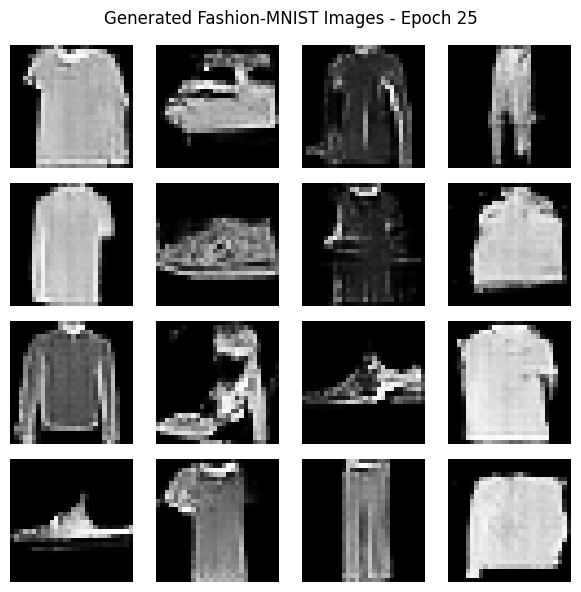

Epoch 26/30 | G Loss: 0.8229 | D Loss: 1.3731
Epoch 27/30 | G Loss: 0.8217 | D Loss: 1.3736
Epoch 28/30 | G Loss: 0.8217 | D Loss: 1.3740
Epoch 29/30 | G Loss: 0.8204 | D Loss: 1.3739
Epoch 30/30 | G Loss: 0.8204 | D Loss: 1.3745


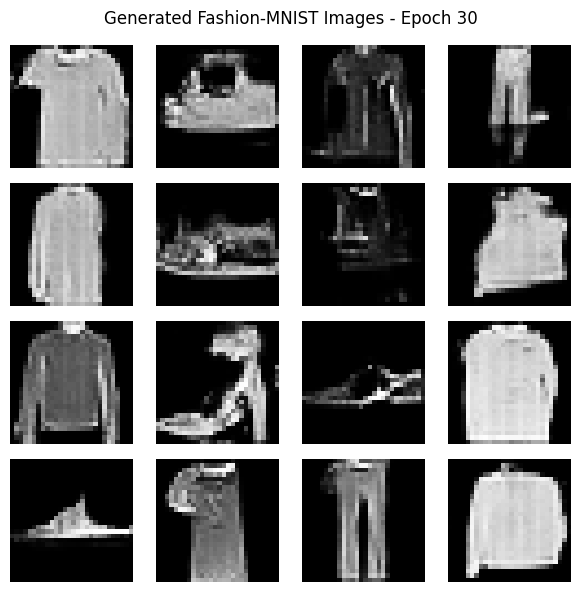

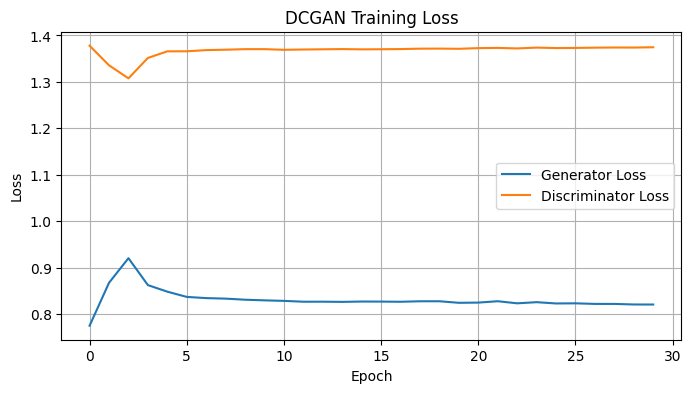

Generator saved successfully.
Part D completed successfully.


In [3]:
# Name: Sastha Jeyasri A.
# Roll No: 24BAD106
# PART D: IMPROVED DCGAN TRAINING

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("GPU:", tf.config.list_physical_devices("GPU"))

# 1. Load and preprocess the full dataset
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5
x_train = x_train[..., np.newaxis]

BATCH_SIZE = 128
NOISE_DIM = 100
EPOCHS = 30

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

# 2. Build an improved Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),
    tf.keras.layers.Dense(7 * 7 * 256, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Reshape((7, 7, 256)),

    tf.keras.layers.Conv2DTranspose(
        128, 4, strides=2, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),

    tf.keras.layers.Conv2DTranspose(
        64, 4, strides=2, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),

    tf.keras.layers.Conv2D(
        1, 3, padding="same", activation="tanh"
    )
], name="Generator")

# 3. Build an improved Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        64, 4, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Conv2D(
        128, 4, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
], name="Discriminator")

# 4. Loss and optimizers
loss_function = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001, beta_1=0.5
)
d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001, beta_1=0.5
)

# 5. Fixed noise for consistent progress comparison
fixed_noise = tf.random.normal([16, NOISE_DIM])

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    # Train Discriminator
    with tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)

        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(
            tf.stop_gradient(fake_images), training=True
        )

        real_loss = loss_function(
            tf.ones_like(real_logits) * 0.9, real_logits
        )
        fake_loss = loss_function(
            tf.zeros_like(fake_logits), fake_logits
        )
        d_loss = real_loss + fake_loss

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as g_tape:
        generated_images = generator(noise, training=True)
        fake_logits = discriminator(generated_images, training=False)

        g_loss = loss_function(
            tf.ones_like(fake_logits), fake_logits
        )

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return g_loss, d_loss

# 6. Display generated images
def show_images(epoch):
    images = generator(fixed_noise, training=False)

    plt.figure(figsize=(6, 6))
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        image = (images[i, :, :, 0].numpy() + 1) / 2
        plt.imshow(image, cmap="gray", vmin=0, vmax=1)
        plt.axis("off")

    plt.suptitle(f"Generated Fashion-MNIST Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()
    plt.close()

# 7. Train the GAN
g_losses = []
d_losses = []

for epoch in range(1, EPOCHS + 1):
    g_metric = tf.keras.metrics.Mean()
    d_metric = tf.keras.metrics.Mean()

    for real_batch in train_dataset:
        g_loss, d_loss = train_step(real_batch)
        g_metric.update_state(g_loss)
        d_metric.update_state(d_loss)

    g_losses.append(float(g_metric.result()))
    d_losses.append(float(d_metric.result()))

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"G Loss: {g_losses[-1]:.4f} | "
        f"D Loss: {d_losses[-1]:.4f}"
    )

    if epoch == 1 or epoch % 5 == 0:
        show_images(epoch)

# 8. Plot losses
plt.figure(figsize=(8, 4))
plt.plot(g_losses, label="Generator Loss")
plt.plot(d_losses, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

# 9. Save the trained Generator
generator.save("fashion_mnist_generator.keras")
print("Generator saved successfully.")
print("Part D completed successfully.")

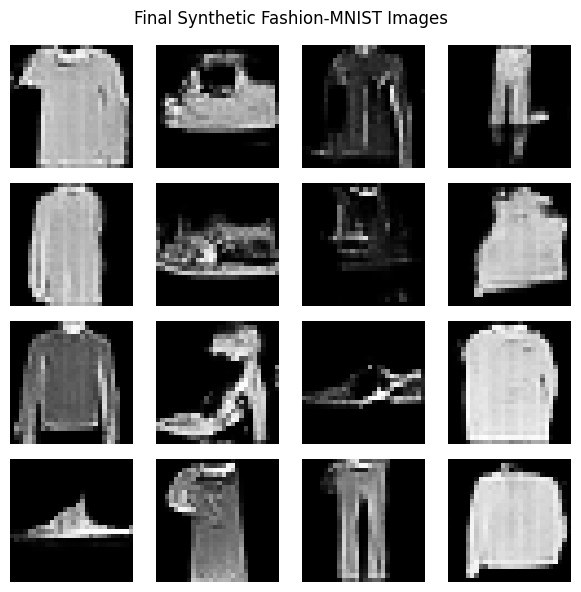

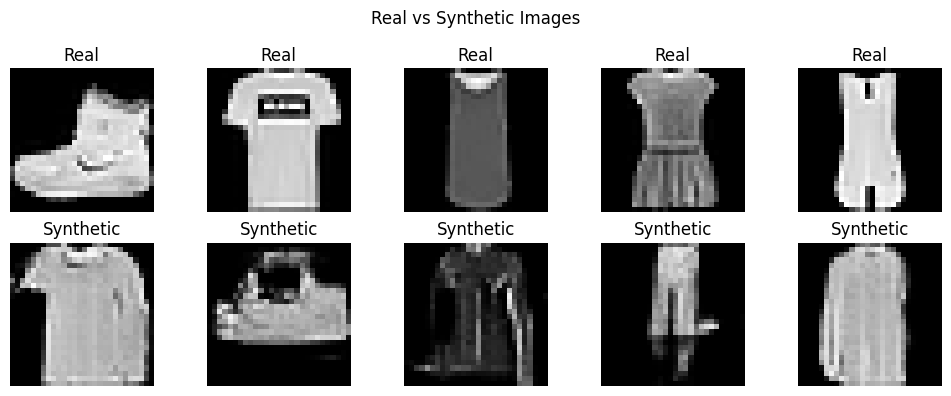

Saved files:
1. final_generated_images.png
2. real_vs_synthetic.png
3. gan_training_loss.png
4. fashion_mnist_generator.keras
Part D completed successfully.


In [5]:
# Step 10: Save the final generated images

final_images = generator(fixed_noise, training=False)

plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    img = (final_images[i, :, :, 0].numpy() + 1) / 2
    plt.imshow(img, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")

plt.suptitle("Final Synthetic Fashion-MNIST Images")
plt.tight_layout()
plt.savefig("final_generated_images.png", dpi=150)
plt.show()
plt.close()


# Step 11: Compare real and synthetic images

plt.figure(figsize=(10, 4))

for i in range(5):
    # Real image
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray", vmin=-1, vmax=1)
    plt.title("Real")
    plt.axis("off")

    # Synthetic image
    plt.subplot(2, 5, i + 6)
    plt.imshow(
        final_images[i, :, :, 0].numpy(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    plt.title("Synthetic")
    plt.axis("off")

plt.suptitle("Real vs Synthetic Images")
plt.tight_layout()
plt.savefig("real_vs_synthetic.png", dpi=150)
plt.show()
plt.close()

# Step 12: Save the trained Generator

generator.save("fashion_mnist_generator.keras")

print("Saved files:")
print("1. final_generated_images.png")
print("2. real_vs_synthetic.png")
print("3. gan_training_loss.png")
print("4. fashion_mnist_generator.keras")
print("Part D completed successfully.")